In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import numpy as np
import numpy as np
from scipy.optimize import curve_fit

from notebooks.imports import *
from src.utils import pmf_utils


### Config

In [3]:
from config import dir_config, main_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

In [43]:
def plot_psych(x, y, x_hat, y_hat) -> None:
    fig, ax = plt.subplots()
    ax.plot(x, y, "o", label="Original Data")
    ax.plot(x_hat, y_hat, "r-", label="Fitted Curve")
    ax.set_xlabel("Coherence")
    ax.set_ylabel("Probability of Correct Response")
    ax.set_xlim(-100, 100)
    ax.set_ylim(0, 1)
    ax.legend()
    plt.show()

def get_pulse_data(data, pulse_type):
    pulse_data = data[(data.pulse_type == pulse_type)]
    if pulse_type > 0:
        # include positive 100 control data too
        positive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == 100)]
        pulse_data = pd.concat([pulse_data, positive_control_data])
    elif pulse_type < 0:
        negavtive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == -100)]
        pulse_data = pd.concat([pulse_data, negavtive_control_data])
    return pulse_data

def plot_pulse_psych(psych_curves, ms=10, lw=3, ls="-", alpha=1.0, suptitle="", marker='o', fig=None, ax=None, legend=True, plot_zero = False):
    """
    Plot psychometric curves for early, mid, and late pulses with control, positive, and negative conditions.
    """

    # Create figure and axes if not provided
    if fig is None or ax is None:
        fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    # Mapping of pulse stage to subplot index
    pulse_map = {1: 0, 2: 1, 3: 2}
    pulse_labels = {1: "Early Pulse", 2: "Mid Pulse", 3: "Late Pulse"}

    def plot_single_pulse(ax, pulse_id, title):
        """Helper to plot a single pulse stage (early, mid, late)."""
        # Plot control
        if plot_zero:
            ax.plot(psych_curves[0]["x"], psych_curves[0]["y"], "k", marker=marker, ms=ms, alpha=alpha, linestyle='None')
            ax.plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k", lw=lw, ls=ls, alpha=alpha, label="Control")
            if psych_curves[0].get("y_err") is not None:
                ax.errorbar(psych_curves[0]["x"], psych_curves[0]["y"], yerr=psych_curves[0]["y_err"], fmt="none", ecolor="k", alpha=alpha)

        # Plot positive pulse
        ax.plot(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], "b", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(psych_curves[pulse_id]["x_hat"], psych_curves[pulse_id]["y_hat"], "b", lw=lw, ls=ls, alpha=alpha, label=f"{title.split()[0]} Positive")
        if psych_curves[pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], yerr=psych_curves[pulse_id]["y_err"], fmt="none", ecolor="b", alpha=alpha)

        # Plot negative pulse
        ax.plot(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], "r", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(psych_curves[-pulse_id]["x_hat"], psych_curves[-pulse_id]["y_hat"], "r", lw=lw, ls=ls, alpha=alpha, label=f"{title.split()[0]} Negative")
        if psych_curves[-pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], yerr=psych_curves[-pulse_id]["y_err"], fmt="none", ecolor="r", alpha=alpha)

        # Formatting
        ax.set(xlabel="Coherence", ylabel="Probability of Positive Response", title=title, xlim=(-105, 105), ylim=(-0.05, 1.05))
        ax.set_xticks(psych_curves[0]["x"])
        ax.tick_params(axis="both", labelsize=16)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(False)
        if legend:
            ax.legend()

    # Iterate through pulse stages that exist in psych_curves
    for pulse_id, idx in pulse_map.items():
        if pulse_id in psych_curves:
            plot_single_pulse(ax[idx], pulse_id, pulse_labels[pulse_id])

    if suptitle:
        fig.suptitle(suptitle, fontsize=24)

    fig.tight_layout()
    return fig, ax

In [5]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
# data = data[data["subject_id"] != "DBM6"]
# data = data[data.reaction_time < main_config.acceptance_criteria.max_reaction_time]


data.groupby("subject_id").agg(n_sessions=("session_id", "nunique"), n_rows=("session_id", "size")).reset_index()


,subject_id,n_sessions,n_rows
0,DBM12,1,959
1,DBM14,3,1780
2,DBM15,2,820
3,DBM5,7,4176
4,DBM6,8,4302
5,PSUIM10,3,1229
6,PSUIM5,6,3002
7,PSUIM6,23,9553
8,PSUIM7,11,7263
9,PSUIM9,3,1048


### Plot psychometric functions

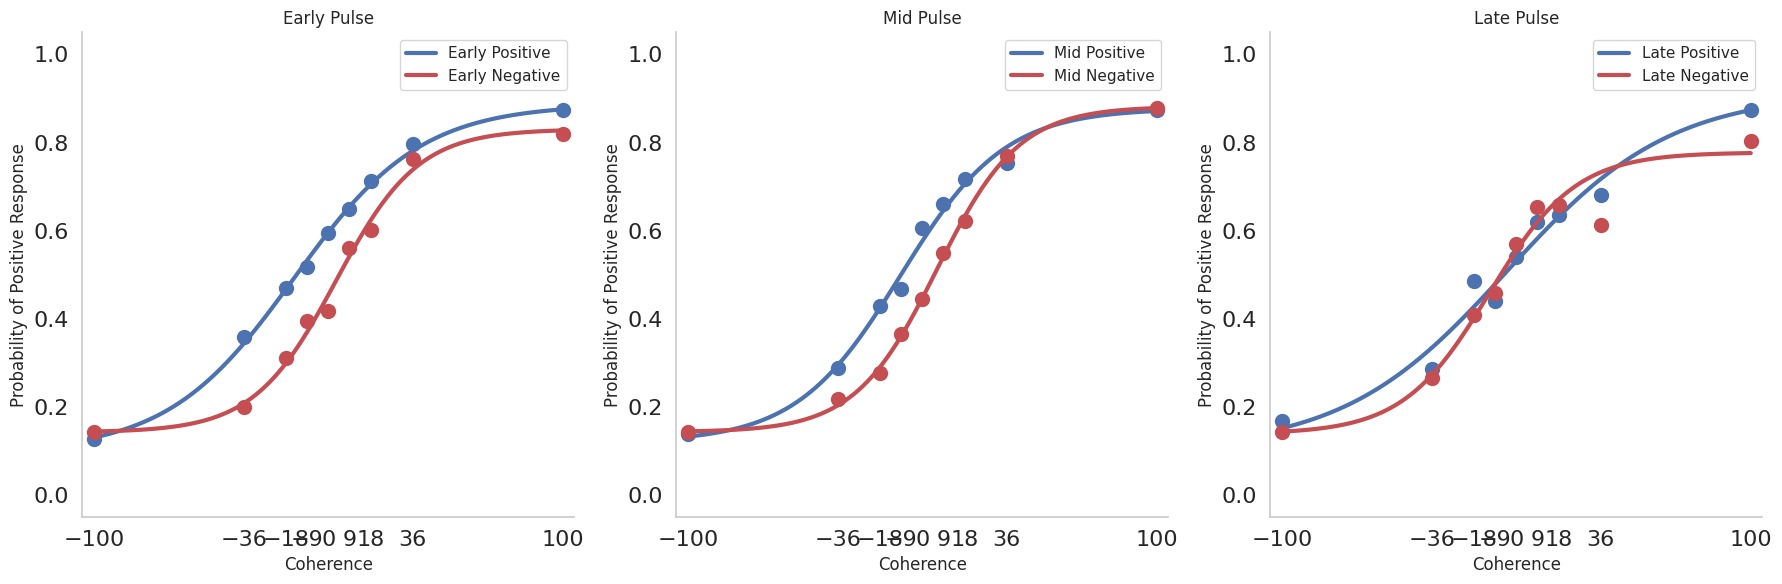

In [6]:
# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():


    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }

plot_pulse_psych(psych_curves);

In [7]:
params, params_se = [], []
for pulse_type in [-3, -2, -1, 0, 1, 2, 3]:
    params.append(np.array(list(psych_curves[pulse_type]["model"].coefs_.values()), dtype=float))
    params_se.append(np.sqrt(np.diag(psych_curves[pulse_type]["model"].covar_)))
params = np.array(params)
params_se = np.array(params_se)

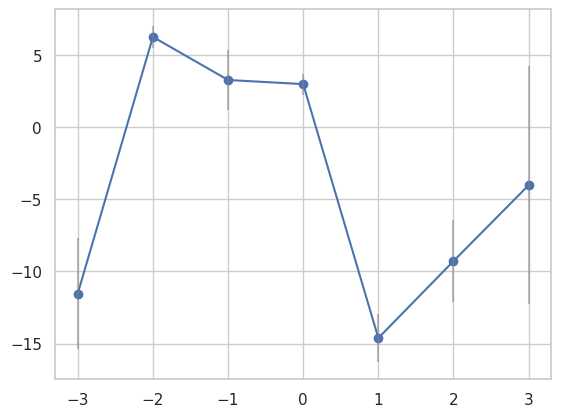

In [8]:
plt.plot([-3, -2, -1, 0, 1, 2, 3], params[:, 0], "o-")
# plot error bars
plt.errorbar([-3, -2, -1, 0, 1, 2, 3], params[:, 0], yerr=params_se[:, 0], fmt="none", ecolor="gray", alpha=0.5);

## Kiani 2008

### Effect of Pulse

In [ ]:
def pulse_glm_function(x, alpha_1, alpha_2, beta_1, beta_2, lapse, gamma):
    """
    Logistic psychometric function with pulse modulation.
    x: 2D array, shape (2, n) -> [signed_coherence, pulse_dir]
    """
    coh = x[0, :]
    pulse_dir = x[1, :]
    alpha = alpha_1 + alpha_2 * pulse_dir
    beta = beta_1 + beta_2 * pulse_dir
    expon_eq = -beta * (coh + alpha)
    return lapse + (1 - gamma - lapse) / (1 + np.exp(expon_eq))


def pulse_glm_fit(x_array, y, trial_counts=None):
    # Parameter bounds
    param_lims = [
        (-1, 1),  # alpha_1
        (-1, 1),  # alpha_2
        (-30, 30),  # beta_1
        (-30, 30),  # beta_2
        (0, 0.4),  # lapse
        (0, 0.4),  # gamma
    ]

    bounds = list(zip(*param_lims))
    initial_guess = [np.mean(b) for b in param_lims]

    sigma = None
    if trial_counts is not None:
        weights = np.sqrt(trial_counts)
        sigma = 1 / weights

    popt, pcov = curve_fit(pulse_glm_function, x_array, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

    return popt, pcov


def get_pulse_psych_data(data):
    psych_curves = {}

    coherences = np.sort(np.unique(data["signed_coherence"]))
    all_signed_coh = []
    all_pulse_dir = []
    y_data = []
    trial_counts = []

    # Loop over pulse types
    for pulse in [-1, 1]:
        pulse_data = data[np.sign(data["pulse_type"]) == pulse]

        signed_coherence = []
        pulse_dir = []
        y = []
        counts = []

        for coh in coherences:
            mask = pulse_data["signed_coherence"] == coh
            n_trials = np.sum(mask)
            if n_trials == 0:
                continue

            signed_coherence.append(coh)
            pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            y.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            counts.append(n_trials)

            all_signed_coh.append(coh)
            all_pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            y_data.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            trial_counts.append(n_trials)

        psych_curves[pulse] = {
            "x": np.array(signed_coherence),
            "y": np.array(y),
        }

    # Prepare arrays for fitting
    x_array = np.vstack([np.array(all_signed_coh), np.array(all_pulse_dir)])
    y_data = np.array(y_data)
    trial_counts = np.array(trial_counts)

    # Fit model
    popt, pcov = pulse_glm_fit(x_array, y_data, trial_counts)
    perr = np.sqrt(np.diag(pcov))

    # Generate predicted curves
    x_hat = np.linspace(-100, 100, 201)
    for pulse_type in [-1, 1]:
        pulse_array = np.full_like(x_hat, 0 if pulse_type == 0 else np.sign(pulse_type))
        y_hat = pulse_glm_function(np.vstack([x_hat, pulse_array]), *popt)

        psych_curves[pulse_type]["x_hat"] = x_hat
        psych_curves[pulse_type]["y_hat"] = y_hat

    return psych_curves, popt, perr


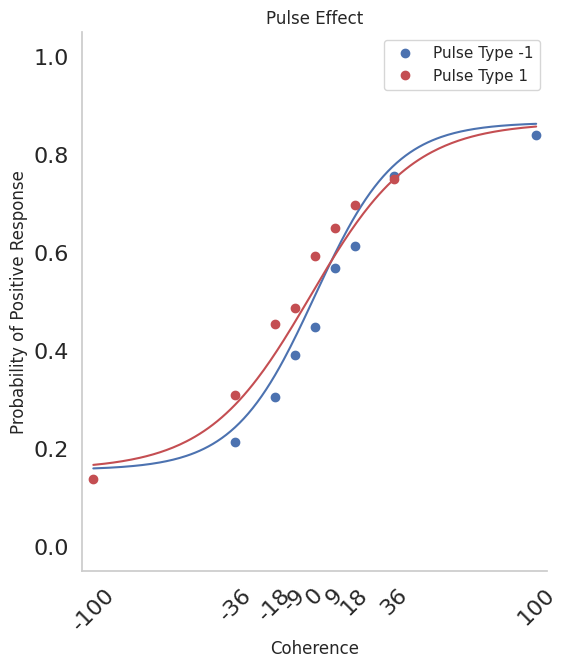

In [24]:
psych_curves, params, param_se = get_pulse_psych_data(data)

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(6, 7))
colors = {-1: "b", 1: "r"}  # Add 0: 'g' if you have zero pulse trials

for pulse_type in psych_curves:
    ax.plot(psych_curves[pulse_type]["x"], psych_curves[pulse_type]["y"], "o", label=f"Pulse Type {pulse_type}", color=colors[pulse_type])
    ax.plot(psych_curves[pulse_type]["x_hat"], psych_curves[pulse_type]["y_hat"], "-", color=colors[pulse_type])

ax.set(xlabel="Coherence", ylabel="Probability of Positive Response", title="Pulse Effect", xlim=(-105, 105), ylim=(-0.05, 1.05))

# Set xticks and rotate labels
xticks = np.unique(data["signed_coherence"])
ax.set_xticks(xticks)
ax.set_xticklabels(xticks, rotation=45)

ax.tick_params(axis="both", labelsize=16)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
ax.legend()
plt.show()


### Effect of Pulse and Time

In [44]:
def pulse_glm_function(x, alpha_1, alpha_2, alpha_3, alpha_4, beta_1, beta_2, beta_3, beta_4, lapse, gamma):
    """
    Logistic psychometric function with pulse modulation.
    x: 2D array, shape (2, n) -> [signed_coherence, pulse_dir]
    """
    coh = x[0, :]
    pulse_dir = x[1, :]
    pulse_time = x[2, :]
    alpha = alpha_1 + (alpha_2 * pulse_dir) + (alpha_3 * pulse_time) + (alpha_4 * pulse_dir * pulse_time)
    beta = beta_1 + (beta_2 * pulse_dir) + (beta_3 * pulse_time) + (beta_4 * pulse_dir * pulse_time)
    expon_eq = -beta * (coh + alpha)
    return lapse + (1 - gamma - lapse) / (1 + np.exp(expon_eq))


def pulse_glm_fit(x_array, y, trial_counts=None):
    # Parameter bounds
    param_lims = [
        (-30, 30),  # alpha_1
        (-30, 30),  # alpha_2
        (-30, 30),  # alpha_3
        (-30, 30),  # alpha_4
        (-30, 30),  # beta_1
        (-30, 30),  # beta_1
        (-30, 30),  # beta_3
        (-30, 30),  # beta_4
        (0, 0.4),  # lapse
        (0, 0.4),  # gamma
    ]

    bounds = list(zip(*param_lims))
    initial_guess = [np.mean(b) for b in param_lims]

    sigma = None
    if trial_counts is not None:
        weights = np.sqrt(trial_counts)
        sigma = 1 / weights

    popt, pcov = curve_fit(pulse_glm_function, x_array, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

    return popt, pcov


def get_pulse_psych_data(data):
    psych_curves = {}

    coherences = np.sort(np.unique(data["signed_coherence"]))
    all_signed_coh = []
    all_pulse_dir = []
    all_pulse_time = []
    y_data = []
    trial_counts = []

    # Loop over pulse types
    for pulse in [-3, -2, -1, 0, 1, 2, 3]:
        pulse_data = data[data["pulse_type"] == pulse]

        signed_coherence = []
        pulse_dir = []
        pulse_time = []
        y = []
        counts = []

        for coh in coherences:
            mask = pulse_data["signed_coherence"] == coh
            n_trials = np.sum(mask)
            if n_trials == 0:
                continue

            signed_coherence.append(coh)
            pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            pulse_time.append(abs(pulse))
            y.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            counts.append(n_trials)

            all_signed_coh.append(coh)
            all_pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            all_pulse_time.append(abs(pulse))
            y_data.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            trial_counts.append(n_trials)

        psych_curves[pulse] = {
            "x": np.array(signed_coherence),
            "y": np.array(y),
        }

    # Prepare arrays for fitting
    x_array = np.vstack([np.array(all_signed_coh), np.array(all_pulse_dir), np.array(all_pulse_time)])
    y_data = np.array(y_data)
    trial_counts = np.array(trial_counts)

    # Fit model
    popt, pcov = pulse_glm_fit(x_array, y_data, trial_counts)
    perr = np.sqrt(np.diag(pcov))

    # Generate predicted curves
    x_hat = np.linspace(-100, 100, 201)
    for pulse_type in [-3, -2, -1, 0, 1, 2, 3]:
        pulse_dir = np.full_like(x_hat, 0 if pulse_type == 0 else np.sign(pulse_type))
        pulse_time = np.full_like(x_hat, abs(pulse_type))
        y_hat = pulse_glm_function(np.vstack([x_hat, pulse_dir, pulse_time]), *popt)

        psych_curves[pulse_type]["x_hat"] = x_hat
        psych_curves[pulse_type]["y_hat"] = y_hat

    return psych_curves, popt, perr


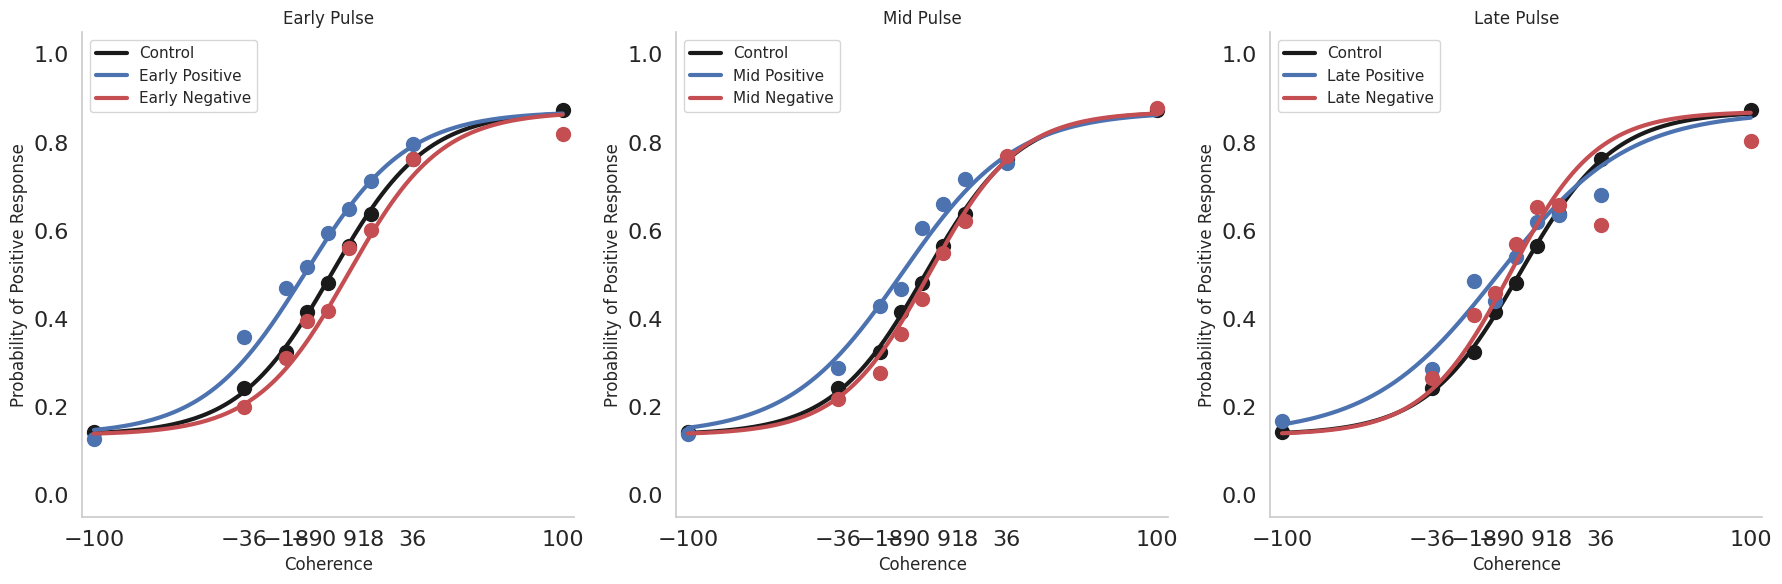

In [ ]:
psych_curves, params, param_se = get_pulse_psych_data(data)
plot_pulse_psych(psych_curves, plot_zero=True);


In [47]:
params


array([-1.48707314e+00,  1.27421312e+01,  2.16704864e+00, -3.46176065e+00,
        4.99156144e-02,  9.71497844e-04, -1.48869123e-03, -3.24748326e-03,
        1.36724180e-01,  1.29575811e-01])